In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_log_error,
    d2_absolute_error_score
)

In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Лабораторна робота №3
## Лінійна регресія та попередня обробка даних

## Завдання 1. Підготовка набору даних
### 1.1 Вибір та завантаження набору даних
Для виконання лабораторної роботи використано набір даних AI Job Market Dataset.

In [4]:
df = pd.read_csv("AI Job Market Dataset.csv")
df.head()

,job_id,job_title,company_size,company_industry,country,remote_type,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,hiring_urgency,job_openings
0,1,AI Engineer,Startup,Retail,Canada,Remote,Senior,2,Master,0,0,0,1,0,158322,6,2024,Low,4
1,2,Machine Learning Engineer,MNC,Technology,Australia,Hybrid,Mid,0,Bachelor,1,1,1,0,1,163666,11,2026,High,9
2,3,Machine Learning Engineer,MNC,Technology,Germany,Onsite,Mid,14,Master,1,0,1,0,1,158556,3,2026,High,9
3,4,Business Analyst,Startup,Healthcare,Germany,Remote,Mid,9,Master,0,1,0,1,1,95775,3,2025,High,7
4,5,Data Scientist,MNC,Healthcare,Germany,Hybrid,Mid,5,Master,1,1,1,0,0,111873,12,2021,Low,2


In [10]:
print("Розмір датасету:", df.shape)
print()
df.dtypes

Розмір датасету: (10345, 19)



job_id                  int64
job_title                 str
company_size              str
company_industry          str
country                   str
remote_type               str
experience_level          str
years_experience        int64
education_level           str
skills_python           int64
skills_sql              int64
skills_ml               int64
skills_deep_learning    int64
skills_cloud            int64
salary                  int64
job_posting_month       int64
job_posting_year        int64
hiring_urgency            str
job_openings            int64
dtype: object

### 1.2 Базова підготовка даних
Вибираємо лише числові стовпці, перевіряємо пропуски та виконуємо фільтрацію аномалій.

In [11]:
numeric_df = df.select_dtypes(include=["int64", "float64"]).copy()
numeric_df.head()

,job_id,years_experience,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,job_openings
0,1,2,0,0,0,1,0,158322,6,2024,4
1,2,0,1,1,1,0,1,163666,11,2026,9
2,3,14,1,0,1,0,1,158556,3,2026,9
3,4,9,0,1,0,1,1,95775,3,2025,7
4,5,5,1,1,1,0,0,111873,12,2021,2


In [8]:
numeric_df.isnull().sum()

job_id                  0
years_experience        0
skills_python           0
skills_sql              0
skills_ml               0
skills_deep_learning    0
skills_cloud            0
salary                  0
job_posting_month       0
job_posting_year        0
job_openings            0
dtype: int64

In [9]:
for col in numeric_df.columns:
    if numeric_df[col].isnull().sum() > 0:
        numeric_df[col] = numeric_df[col].fillna(numeric_df[col].median())

numeric_df.isnull().sum()

job_id                  0
years_experience        0
skills_python           0
skills_sql              0
skills_ml               0
skills_deep_learning    0
skills_cloud            0
salary                  0
job_posting_month       0
job_posting_year        0
job_openings            0
dtype: int64

In [12]:
target_column = "salary"

feature_columns = [
    "years_experience",
    "skills_python",
    "skills_sql",
    "skills_ml",
    "skills_deep_learning",
    "skills_cloud",
    "job_posting_month",
    "job_posting_year",
    "job_openings"
]

data = numeric_df[feature_columns + [target_column]].copy()
data.head()

,years_experience,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,job_posting_month,job_posting_year,job_openings,salary
0,2,0,0,0,1,0,6,2024,4,158322
1,0,1,1,1,0,1,11,2026,9,163666
2,14,1,0,1,0,1,3,2026,9,158556
3,9,0,1,0,1,1,3,2025,7,95775
4,5,1,1,1,0,0,12,2021,2,111873


In [13]:
clean_data = data.copy()

for col in feature_columns + [target_column]:
    Q1 = clean_data[col].quantile(0.25)
    Q3 = clean_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    clean_data = clean_data[(clean_data[col] >= lower) & (clean_data[col] <= upper)]

print("Було рядків:", len(data))
print("Стало рядків після видалення аномалій:", len(clean_data))

Було рядків: 10345
Стало рядків після видалення аномалій: 10341


### 1.3 Знаходження залежностей
Обчислюємо кореляційну матрицю, будуємо теплову карту та визначаємо ознаки з найсильнішим зв’язком із цільовою змінною.

In [14]:
corr_matrix = clean_data.corr()
corr_matrix

,years_experience,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,job_posting_month,job_posting_year,job_openings,salary
years_experience,1.000000,0.006451,-0.000536,-0.018611,-0.010190,0.000454,-0.007658,-0.007444,-0.018712,-0.012595
skills_python,0.006451,1.000000,-0.004076,-0.001628,-0.005765,0.014914,0.013889,0.010075,-0.006002,0.010093
skills_sql,-0.000536,-0.004076,1.000000,0.008127,0.007086,0.004022,-0.002218,-0.018888,0.003320,-0.003472
skills_ml,-0.018611,-0.001628,0.008127,1.000000,0.006740,-0.000056,-0.005621,0.006684,0.012961,0.231941
skills_deep_learning,-0.010190,-0.005765,0.007086,0.006740,1.000000,-0.011219,-0.006275,-0.010364,0.022878,0.241821
skills_cloud,0.000454,0.014914,0.004022,-0.000056,-0.011219,1.000000,-0.013563,-0.003294,0.009206,0.152911
job_posting_month,-0.007658,0.013889,-0.002218,-0.005621,-0.006275,-0.013563,1.000000,-0.012534,0.011383,-0.013578
job_posting_year,-0.007444,0.010075,-0.018888,0.006684,-0.010364,-0.003294,-0.012534,1.000000,-0.006355,0.002479
job_openings,-0.018712,-0.006002,0.003320,0.012961,0.022878,0.009206,0.011383,-0.006355,1.000000,0.006480
salary,-0.012595,0.010093,-0.003472,0.231941,0.241821,0.152911,-0.013578,0.002479,0.006480,1.000000


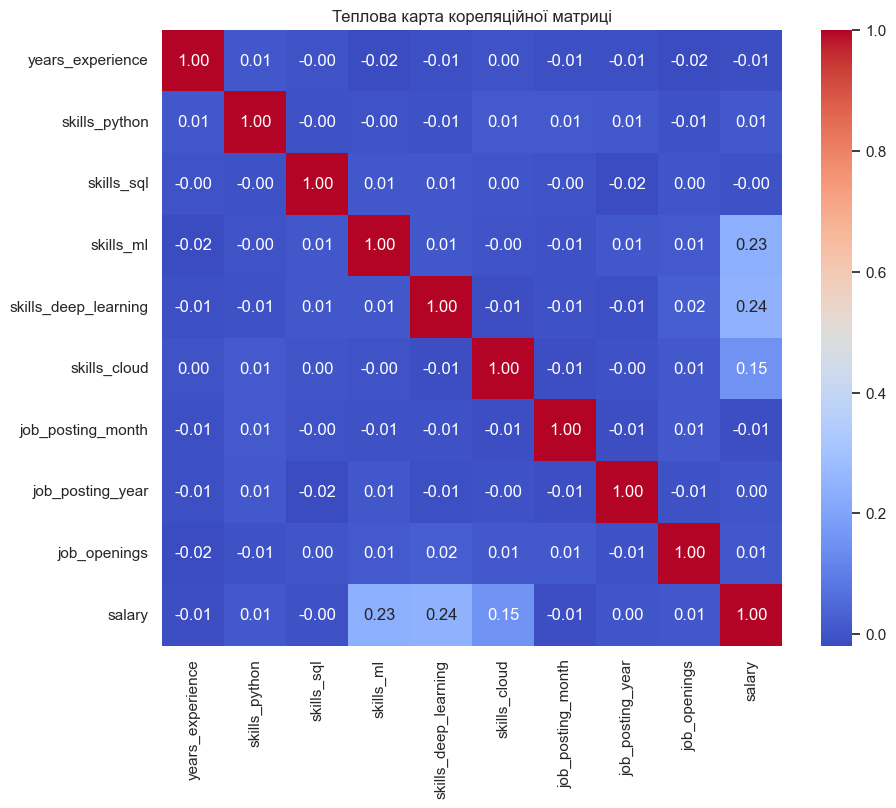

In [15]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Теплова карта кореляційної матриці")
plt.show()

In [16]:
target_corr = corr_matrix[target_column].drop(target_column).sort_values(key=np.abs, ascending=False)
target_corr

skills_deep_learning    0.241821
skills_ml               0.231941
skills_cloud            0.152911
job_posting_month      -0.013578
years_experience       -0.012595
skills_python           0.010093
job_openings            0.006480
skills_sql             -0.003472
job_posting_year        0.002479
Name: salary, dtype: float64

Сильною кореляцією будемо вважати коефіцієнт кореляції за модулем більше 0.7.
Якщо дві ознаки сильно корелюють між собою, для побудови моделі доцільно залишити лише одну з них.

In [17]:
feature_corr = clean_data[feature_columns].corr().abs()
feature_corr

,years_experience,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,job_posting_month,job_posting_year,job_openings
years_experience,1.000000,0.006451,0.000536,0.018611,0.010190,0.000454,0.007658,0.007444,0.018712
skills_python,0.006451,1.000000,0.004076,0.001628,0.005765,0.014914,0.013889,0.010075,0.006002
skills_sql,0.000536,0.004076,1.000000,0.008127,0.007086,0.004022,0.002218,0.018888,0.003320
skills_ml,0.018611,0.001628,0.008127,1.000000,0.006740,0.000056,0.005621,0.006684,0.012961
skills_deep_learning,0.010190,0.005765,0.007086,0.006740,1.000000,0.011219,0.006275,0.010364,0.022878
skills_cloud,0.000454,0.014914,0.004022,0.000056,0.011219,1.000000,0.013563,0.003294,0.009206
job_posting_month,0.007658,0.013889,0.002218,0.005621,0.006275,0.013563,1.000000,0.012534,0.011383
job_posting_year,0.007444,0.010075,0.018888,0.006684,0.010364,0.003294,0.012534,1.000000,0.006355
job_openings,0.018712,0.006002,0.003320,0.012961,0.022878,0.009206,0.011383,0.006355,1.000000


In [18]:
selected_features = feature_columns.copy()
selected_features

['years_experience',
 'skills_python',
 'skills_sql',
 'skills_ml',
 'skills_deep_learning',
 'skills_cloud',
 'job_posting_month',
 'job_posting_year',
 'job_openings']

In [19]:
X = clean_data[selected_features]
y = clean_data[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8272, 9)
X_test: (2069, 9)
y_train: (8272,)
y_test: (2069,)


In [20]:
main_feature = target_corr.index[0]
print("Найбільш пов’язана з salary ознака:", main_feature)

Найбільш пов’язана з salary ознака: skills_deep_learning


In [23]:
def calculate_metrics(y_train_true, y_train_pred, y_test_true, y_test_pred, train_score, test_score):
    return pd.DataFrame({
        "R2_score": [train_score, test_score],
        "MAE": [
            mean_absolute_error(y_train_true, y_train_pred),
            mean_absolute_error(y_test_true, y_test_pred)
        ],
        "MSLE": [
            mean_squared_log_error(y_train_true, np.maximum(y_train_pred, 0)),
            mean_squared_log_error(y_test_true, np.maximum(y_test_pred, 0))
        ],
        "D2_absolute_error_score": [
            d2_absolute_error_score(y_train_true, y_train_pred),
            d2_absolute_error_score(y_test_true, y_test_pred)
        ]
    }, index=["Train", "Test"])

## 2.1 Проста лінійна регресія

In [24]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_train_pred_lr = lr_model.predict(X_train)
y_test_pred_lr = lr_model.predict(X_test)

lr_metrics = calculate_metrics(
    y_train, y_train_pred_lr,
    y_test, y_test_pred_lr,
    lr_model.score(X_train, y_train),
    lr_model.score(X_test, y_test)
)

lr_metrics

,R2_score,MAE,MSLE,D2_absolute_error_score
Train,0.132081,23792.331213,0.075736,0.071736
Test,0.150146,23427.253663,0.070731,0.080366


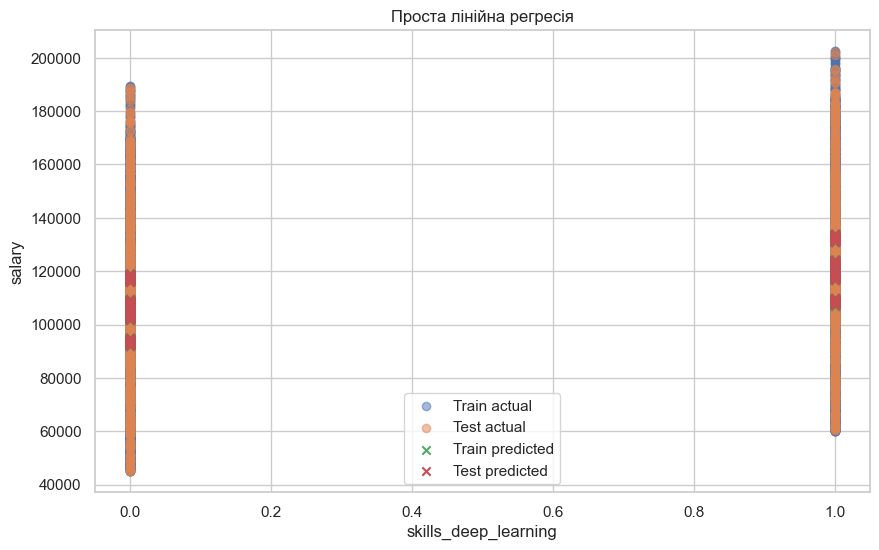

In [25]:
plt.figure(figsize=(10, 6))

plt.scatter(X_train[main_feature], y_train, label="Train actual", alpha=0.5)
plt.scatter(X_test[main_feature], y_test, label="Test actual", alpha=0.5)

plt.scatter(X_train[main_feature], y_train_pred_lr, label="Train predicted", marker="x")
plt.scatter(X_test[main_feature], y_test_pred_lr, label="Test predicted", marker="x")

plt.xlabel(main_feature)
plt.ylabel("salary")
plt.title("Проста лінійна регресія")
plt.legend()
plt.show()

Висновок: за отриманими метриками оцінюється точність моделі на тренувальній і тестовій вибірках. Якщо значення метрик на тесті близькі до тренувальних, модель краще узагальнює дані.

## 2.2 Проста лінійна регресія з перетворенням змінних
Перед навчанням виконується перетворення усіх змінних до розподілу, наближеного до нормального.

In [26]:
pt_X = PowerTransformer()
pt_y = PowerTransformer()

X_train_trans = pt_X.fit_transform(X_train)
X_test_trans = pt_X.transform(X_test)

y_train_trans = pt_y.fit_transform(y_train.to_frame()).ravel()
y_test_trans = pt_y.transform(y_test.to_frame()).ravel()

In [28]:
lr_trans_model = LinearRegression()
lr_trans_model.fit(X_train_trans, y_train_trans)

y_train_pred_lr_trans = lr_trans_model.predict(X_train_trans)
y_test_pred_lr_trans = lr_trans_model.predict(X_test_trans)

# Повертаємо значення до початкового масштабу salary
y_train_pred_lr_trans_original = pt_y.inverse_transform(y_train_pred_lr_trans.reshape(-1, 1)).ravel()
y_test_pred_lr_trans_original = pt_y.inverse_transform(y_test_pred_lr_trans.reshape(-1, 1)).ravel()

# Справжні значення теж беремо в початковому масштабі
y_train_original = y_train.values
y_test_original = y_test.values

lr_trans_metrics = calculate_metrics(
    y_train_original, y_train_pred_lr_trans_original,
    y_test_original, y_test_pred_lr_trans_original,
    lr_trans_model.score(X_train_trans, y_train_trans),
    lr_trans_model.score(X_test_trans, y_test_trans)
)

lr_trans_metrics

/Users/viktoriyabilyk/PycharmProjects/lab3/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/Users/viktoriyabilyk/PycharmProjects/lab3/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(


,R2_score,MAE,MSLE,D2_absolute_error_score
Train,0.134511,23871.557164,0.074984,0.068645
Test,0.152562,23491.591067,0.070178,0.077840


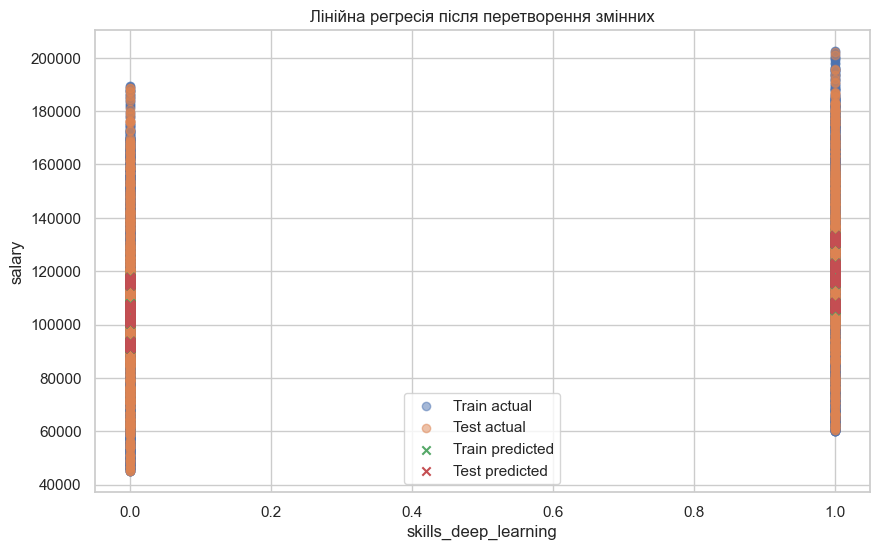

In [29]:
plt.figure(figsize=(10, 6))

plt.scatter(X_train[main_feature], y_train, label="Train actual", alpha=0.5)
plt.scatter(X_test[main_feature], y_test, label="Test actual", alpha=0.5)

plt.scatter(X_train[main_feature], y_train_pred_lr_trans_original, label="Train predicted", marker="x")
plt.scatter(X_test[main_feature], y_test_pred_lr_trans_original, label="Test predicted", marker="x")

plt.xlabel(main_feature)
plt.ylabel("salary")
plt.title("Лінійна регресія після перетворення змінних")
plt.legend()
plt.show()

## 2.3 Гребенева регресія
Будуються три моделі: з параметрами за замовчуванням, а також з двома додатковими значеннями alpha.

In [31]:
ridge_default = Ridge()
ridge_default.fit(X_train, y_train)

y_train_pred_ridge_default = ridge_default.predict(X_train)
y_test_pred_ridge_default = ridge_default.predict(X_test)

ridge_default_metrics = calculate_metrics(
    y_train, y_train_pred_ridge_default,
    y_test, y_test_pred_ridge_default,
    ridge_default.score(X_train, y_train),
    ridge_default.score(X_test, y_test)
)

ridge_default_metrics

,R2_score,MAE,MSLE,D2_absolute_error_score
Train,0.132081,23792.359675,0.075737,0.071735
Test,0.150138,23427.379760,0.070732,0.080361


In [32]:
ridge_10 = Ridge(alpha=10)
ridge_10.fit(X_train, y_train)

y_train_pred_ridge_10 = ridge_10.predict(X_train)
y_test_pred_ridge_10 = ridge_10.predict(X_test)

ridge_10_metrics = calculate_metrics(
    y_train, y_train_pred_ridge_10,
    y_test, y_test_pred_ridge_10,
    ridge_10.score(X_train, y_train),
    ridge_10.score(X_test, y_test)
)

ridge_10_metrics

,R2_score,MAE,MSLE,D2_absolute_error_score
Train,0.132078,23792.687147,0.075747,0.071722
Test,0.150071,23428.583100,0.070744,0.080313


In [33]:
ridge_100 = Ridge(alpha=100)
ridge_100.fit(X_train, y_train)

y_train_pred_ridge_100 = ridge_100.predict(X_train)
y_test_pred_ridge_100 = ridge_100.predict(X_test)

ridge_100_metrics = calculate_metrics(
    y_train, y_train_pred_ridge_100,
    y_test, y_test_pred_ridge_100,
    ridge_100.score(X_train, y_train),
    ridge_100.score(X_test, y_test)
)

ridge_100_metrics

,R2_score,MAE,MSLE,D2_absolute_error_score
Train,0.131796,23799.207031,0.075862,0.071468
Test,0.149163,23444.305780,0.070876,0.079696


In [34]:
ridge_all_metrics = pd.concat({
    "Ridge default": ridge_default_metrics,
    "Ridge alpha=10": ridge_10_metrics,
    "Ridge alpha=100": ridge_100_metrics
})

ridge_all_metrics

R2_score           MAE      MSLE  \
Ridge default   Train  0.132081  23792.359675  0.075737   
                Test   0.150138  23427.379760  0.070732   
Ridge alpha=10  Train  0.132078  23792.687147  0.075747   
                Test   0.150071  23428.583100  0.070744   
Ridge alpha=100 Train  0.131796  23799.207031  0.075862   
                Test   0.149163  23444.305780  0.070876   

                       D2_absolute_error_score  
Ridge default   Train                 0.071735  
                Test                  0.080361  
Ridge alpha=10  Train                 0.071722  
                Test                  0.080313  
Ridge alpha=100 Train                 0.071468  
                Test                  0.079696

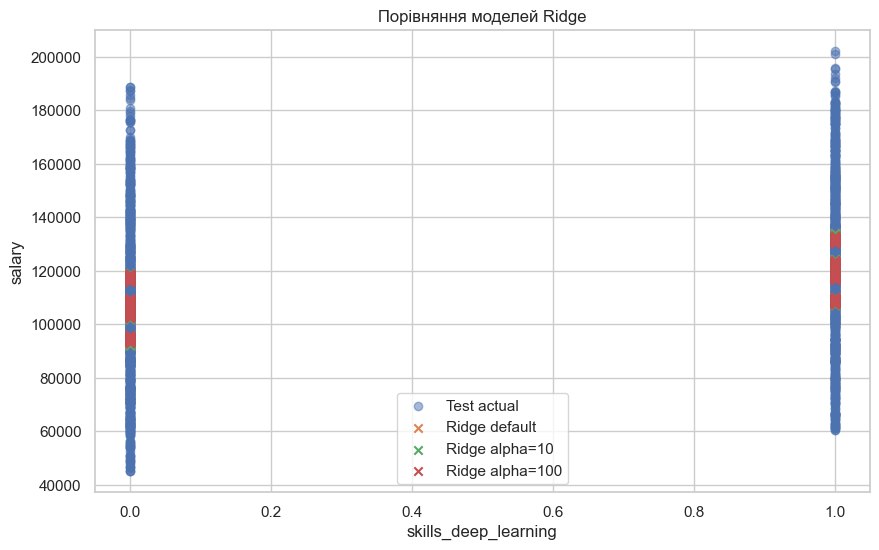

In [35]:
plt.figure(figsize=(10, 6))

plt.scatter(X_test[main_feature], y_test, label="Test actual", alpha=0.5)
plt.scatter(X_test[main_feature], y_test_pred_ridge_default, label="Ridge default", marker="x")
plt.scatter(X_test[main_feature], y_test_pred_ridge_10, label="Ridge alpha=10", marker="x")
plt.scatter(X_test[main_feature], y_test_pred_ridge_100, label="Ridge alpha=100", marker="x")

plt.xlabel(main_feature)
plt.ylabel("salary")
plt.title("Порівняння моделей Ridge")
plt.legend()
plt.show()

## 2.4 Гребенева регресія з перетворенням змінних

In [37]:
ridge_trans_default = Ridge()
ridge_trans_default.fit(X_train_trans, y_train_trans)

y_train_pred_ridge_trans_default = ridge_trans_default.predict(X_train_trans)
y_test_pred_ridge_trans_default = ridge_trans_default.predict(X_test_trans)

# DataFrame для коректного inverse_transform без warning
y_train_pred_ridge_trans_default_df = pd.DataFrame(
    y_train_pred_ridge_trans_default,
    columns=[target_column]
)
y_test_pred_ridge_trans_default_df = pd.DataFrame(
    y_test_pred_ridge_trans_default,
    columns=[target_column]
)

# Повернення прогнозів у початковий масштаб salary
y_train_pred_ridge_trans_default_original = pt_y.inverse_transform(
    y_train_pred_ridge_trans_default_df
).ravel()

y_test_pred_ridge_trans_default_original = pt_y.inverse_transform(
    y_test_pred_ridge_trans_default_df
).ravel()

# Справжні значення у початковому масштабі
y_train_original = y_train.values
y_test_original = y_test.values

ridge_trans_default_metrics = calculate_metrics(
    y_train_original, y_train_pred_ridge_trans_default_original,
    y_test_original, y_test_pred_ridge_trans_default_original,
    ridge_trans_default.score(X_train_trans, y_train_trans),
    ridge_trans_default.score(X_test_trans, y_test_trans)
)

ridge_trans_default_metrics

,R2_score,MAE,MSLE,D2_absolute_error_score
Train,0.134511,23871.558891,0.074985,0.068645
Test,0.152561,23491.626599,0.070178,0.077839


In [38]:
ridge_trans_10 = Ridge(alpha=10)
ridge_trans_10.fit(X_train_trans, y_train_trans)

y_train_pred_ridge_trans_10 = ridge_trans_10.predict(X_train_trans)
y_test_pred_ridge_trans_10 = ridge_trans_10.predict(X_test_trans)

y_train_pred_ridge_trans_10_df = pd.DataFrame(
    y_train_pred_ridge_trans_10,
    columns=[target_column]
)
y_test_pred_ridge_trans_10_df = pd.DataFrame(
    y_test_pred_ridge_trans_10,
    columns=[target_column]
)

y_train_pred_ridge_trans_10_original = pt_y.inverse_transform(
    y_train_pred_ridge_trans_10_df
).ravel()

y_test_pred_ridge_trans_10_original = pt_y.inverse_transform(
    y_test_pred_ridge_trans_10_df
).ravel()

ridge_trans_10_metrics = calculate_metrics(
    y_train.values, y_train_pred_ridge_trans_10_original,
    y_test.values, y_test_pred_ridge_trans_10_original,
    ridge_trans_10.score(X_train_trans, y_train_trans),
    ridge_trans_10.score(X_test_trans, y_test_trans)
)

ridge_trans_10_metrics

,R2_score,MAE,MSLE,D2_absolute_error_score
Train,0.134511,23871.582351,0.074986,0.068644
Test,0.152546,23491.945984,0.070180,0.077826


In [39]:
ridge_trans_100 = Ridge(alpha=100)
ridge_trans_100.fit(X_train_trans, y_train_trans)

y_train_pred_ridge_trans_100 = ridge_trans_100.predict(X_train_trans)
y_test_pred_ridge_trans_100 = ridge_trans_100.predict(X_test_trans)

y_train_pred_ridge_trans_100_df = pd.DataFrame(
    y_train_pred_ridge_trans_100,
    columns=[target_column]
)
y_test_pred_ridge_trans_100_df = pd.DataFrame(
    y_test_pred_ridge_trans_100,
    columns=[target_column]
)

y_train_pred_ridge_trans_100_original = pt_y.inverse_transform(
    y_train_pred_ridge_trans_100_df
).ravel()

y_test_pred_ridge_trans_100_original = pt_y.inverse_transform(
    y_test_pred_ridge_trans_100_df
).ravel()

ridge_trans_100_metrics = calculate_metrics(
    y_train.values, y_train_pred_ridge_trans_100_original,
    y_test.values, y_test_pred_ridge_trans_100_original,
    ridge_trans_100.score(X_train_trans, y_train_trans),
    ridge_trans_100.score(X_test_trans, y_test_trans)
)

ridge_trans_100_metrics

,R2_score,MAE,MSLE,D2_absolute_error_score
Train,0.134491,23872.320107,0.075003,0.068616
Test,0.152388,23495.211031,0.070202,0.077698


In [41]:
ridge_trans_all_metrics = pd.concat({
    "Ridge transformed default": ridge_trans_default_metrics,
    "Ridge transformed alpha=10": ridge_trans_10_metrics,
    "Ridge transformed alpha=100": ridge_trans_100_metrics
})

ridge_trans_all_metrics

R2_score           MAE      MSLE  \
Ridge transformed default   Train  0.134511  23871.558891  0.074985   
                            Test   0.152561  23491.626599  0.070178   
Ridge transformed alpha=10  Train  0.134511  23871.582351  0.074986   
                            Test   0.152546  23491.945984  0.070180   
Ridge transformed alpha=100 Train  0.134491  23872.320107  0.075003   
                            Test   0.152388  23495.211031  0.070202   

                                   D2_absolute_error_score  
Ridge transformed default   Train                 0.068645  
                            Test                  0.077839  
Ridge transformed alpha=10  Train                 0.068644  
                            Test                  0.077826  
Ridge transformed alpha=100 Train                 0.068616  
                            Test                  0.077698

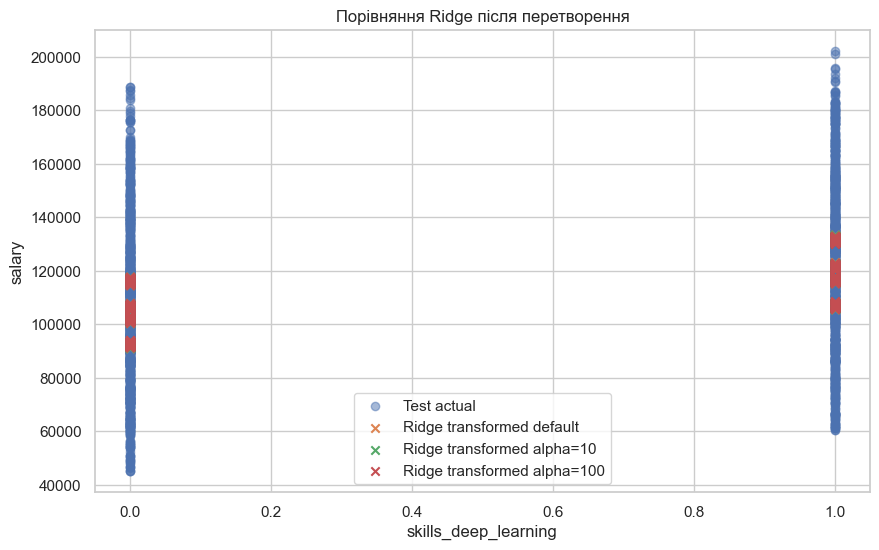

In [40]:
plt.figure(figsize=(10, 6))

plt.scatter(X_test[main_feature], y_test, label="Test actual", alpha=0.5)
plt.scatter(X_test[main_feature], y_test_pred_ridge_trans_default_original, label="Ridge transformed default", marker="x")
plt.scatter(X_test[main_feature], y_test_pred_ridge_trans_10_original, label="Ridge transformed alpha=10", marker="x")
plt.scatter(X_test[main_feature], y_test_pred_ridge_trans_100_original, label="Ridge transformed alpha=100", marker="x")

plt.xlabel(main_feature)
plt.ylabel("salary")
plt.title("Порівняння Ridge після перетворення")
plt.legend()
plt.show()

## 2.5 Сукупне порівняння метрик

In [42]:
all_metrics = pd.concat({
    "Linear Regression": lr_metrics,
    "Linear Regression Transformed": lr_trans_metrics,
    "Ridge default": ridge_default_metrics,
    "Ridge alpha=10": ridge_10_metrics,
    "Ridge alpha=100": ridge_100_metrics,
    "Ridge transformed default": ridge_trans_default_metrics,
    "Ridge transformed alpha=10": ridge_trans_10_metrics,
    "Ridge transformed alpha=100": ridge_trans_100_metrics
})

all_metrics

R2_score           MAE      MSLE  \
Linear Regression             Train  0.132081  23792.331213  0.075736   
                              Test   0.150146  23427.253663  0.070731   
Linear Regression Transformed Train  0.134511  23871.557164  0.074984   
                              Test   0.152562  23491.591067  0.070178   
Ridge default                 Train  0.132081  23792.359675  0.075737   
                              Test   0.150138  23427.379760  0.070732   
Ridge alpha=10                Train  0.132078  23792.687147  0.075747   
                              Test   0.150071  23428.583100  0.070744   
Ridge alpha=100               Train  0.131796  23799.207031  0.075862   
                              Test   0.149163  23444.305780  0.070876   
Ridge transformed default     Train  0.134511  23871.558891  0.074985   
                              Test   0.152561  23491.626599  0.070178   
Ridge transformed alpha=10    Train  0.134511  23871.582351  0.074986   
                              Test   0.152546  23491.945984  0.070180   
Ridge transformed alpha=100   Train  0.134491  23872.320107  0.075003   
                              Test   0.152388  23495.211031  0.070202   

                                     D2_absolute_error_score  
Linear Regression             Train                 0.071736  
                              Test                  0.080366  
Linear Regression Transformed Train                 0.068645  
                              Test                  0.077840  
Ridge default                 Train                 0.071735  
                              Test                  0.080361  
Ridge alpha=10                Train                 0.071722  
                              Test                  0.080313  
Ridge alpha=100               Train                 0.071468  
                              Test                  0.079696  
Ridge transformed default     Train                 0.068645  
                              Test                  0.077839  
Ridge transformed alpha=10    Train                 0.068644  
                              Test                  0.077826  
Ridge transformed alpha=100   Train                 0.068616  
                              Test                  0.077698

In [ ]:
all_metrics.style.background_gradient(cmap="RdYlGn")

## Висновки

У ході виконання лабораторної роботи було завантажено та підготовлено набір даних, перевірено типи даних, оброблено пропуски та видалено аномальні значення. Далі було побудовано кореляційну матрицю і визначено ознаки, що мають найбільший зв’язок із цільовою змінною salary.

Було побудовано моделі простої лінійної регресії, лінійної регресії після перетворення змінних, а також гребеневої регресії з різними значеннями параметра alpha без перетворення і після нього. Для кожної моделі обчислено метрики R2_score, MAE, MSLE та D2 absolute error score окремо для тренувальної і тестової вибірок.

Отримані результати дають змогу порівняти якість моделей і оцінити вплив перетворення змінних та регуляризації на точність прогнозування.